# 08 — Next iteration: setup v2 / 下一步：setup v2

**EN** The one named next step: short-leg tail control. Dev exploration (exploratory only), Monte Carlo robustness (descriptive only) and the status of the registered forward shadow test.

*Needs `data/` and `artifacts/` from the shared Drive folder (see README).*

**中文** 唯一指名的下一步：空頭腿尾部控制。開發期探索（僅探索性）、蒙地卡羅穩健性（僅描述性）與事先登記的前瞻影子期檢定狀態。

*需要先從 README 的 Drive 連結下載 `data/` 與 `artifacts/`。*

In [1]:
# Locate the repository root and load the library (works from the root or notebooks/)
# 找到 repo 根目錄並載入函式庫（從根目錄或 notebooks/ 執行皆可）
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "setup.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)


def show(fig, width=820):
    """Show a committed figure / 顯示已產出的圖"""
    display(Image(filename=str(ROOT / "reports" / "figures" / fig), width=width))


def sh(cmd):
    """Run a repository command from the root and print its output / 在根目錄執行指令並印出結果"""
    r = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-4000:], r.stderr[-2000:])
    return r.returncode

In [2]:
# Dev exploration: v1 vs v2a (liquidation cap) vs v2b (+ short eligibility) / 開發期探索
v2dev = pd.read_csv("reports/setup_v2_dev.csv")
display(v2dev[["signal", "variant", "net_sharpe", "ci_low", "ci_high", "max_drawdown", "cvar95", "worst_day", "liquidations"]])

,signal,variant,net_sharpe,ci_low,ci_high,max_drawdown,cvar95,worst_day,liquidations
0,ridge,v1,-0.1878,-1.3908,1.0152,0.4853,0.0416,-0.1978,0
1,ridge,v2a,0.0784,-1.1245,1.2814,0.3574,0.0324,-0.0609,174
2,ridge,v2b,0.4708,-0.7323,1.6740,0.1969,0.0187,-0.0398,65
3,rule_carry,v1,0.4671,-0.7360,1.6702,0.3645,0.0290,-0.2365,0
4,rule_carry,v2a,0.8479,-0.3557,2.0514,0.1841,0.0218,-0.0585,105


share_v2a_better              mean_d_mdd              
events_per_year               2      8     24         2      8      24
retention peak                                                        
0.0       1.5               1.00  1.000  1.00     -0.128 -0.127 -0.126
          2.5               0.99  0.115  0.00     -0.110 -0.055  0.124
          4.0               0.99  0.085  0.00     -0.109 -0.053  0.135
0.5       1.5               1.00  1.000  1.00     -0.126 -0.116 -0.089
          2.5               1.00  1.000  0.07     -0.114 -0.083 -0.063
          4.0               1.00  1.000  1.00     -0.120 -0.165 -0.222
1.0       1.5               1.00  1.000  1.00     -0.122 -0.102 -0.112
          2.5               1.00  1.000  1.00     -0.120 -0.165 -0.223
          4.0               1.00  1.000  1.00     -0.153 -0.311 -0.346

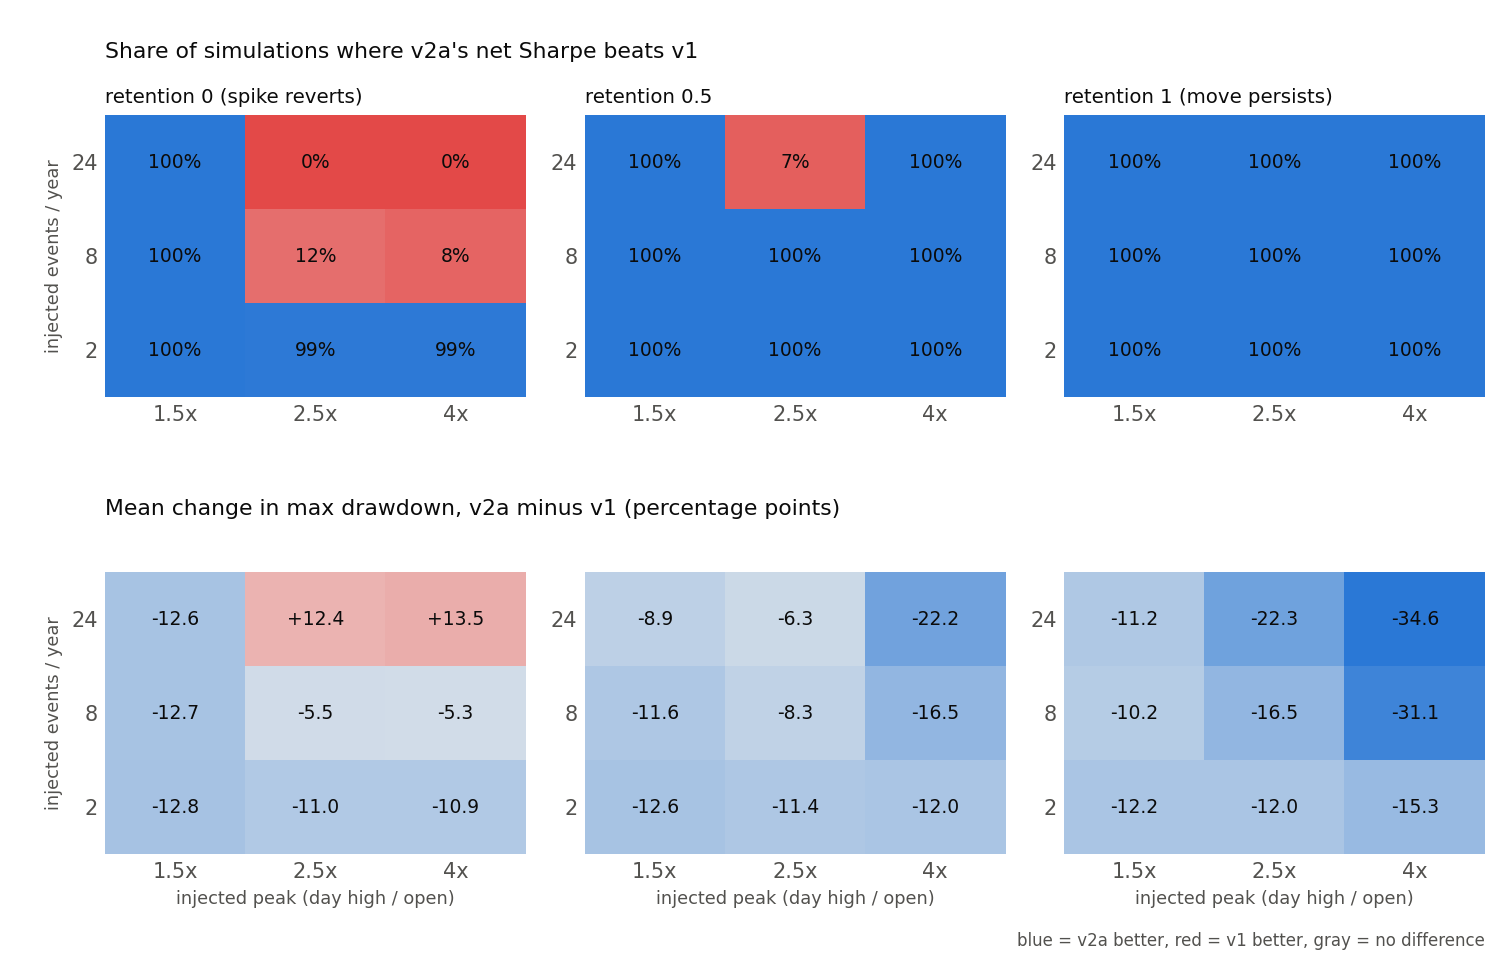

In [3]:
# Monte Carlo: squeeze-injection grid summary / 蒙地卡羅：注入軋空情境的網格摘要
A = pd.read_csv("reports/setup_v2_mc_A.csv")
A = A.assign(v2a_better=A["sharpe_v2a"] > A["sharpe_v1"], d_mdd=A["mdd_v2a"] - A["mdd_v1"])
grid = A.groupby(["retention", "peak", "events_per_year"]).agg(share_v2a_better=("v2a_better", "mean"),
                                                               mean_d_mdd=("d_mdd", "mean"))
display(grid.unstack("events_per_year").round(3))
show("setup_v2_mc_grid.png")

In [4]:
# Paired bootstrap: how often the registered shadow rule would support v2a / 自助法：登記規則支持 v2a 的比例
B = pd.read_csv("reports/setup_v2_mc_B.csv")
B.groupby("length")[["tail_better", "ci_low_positive", "supported"]].mean()

,tail_better,ci_low_positive,supported
length,,,
90,0.4655,0.0010,0.4595
180,0.5780,0.0000,0.5700
969,0.9040,0.0195,0.8970


In [5]:
# Shadow test status (needs >= 90 realized days) / 影子期檢定狀態（需 >= 90 個實現日）
json.loads(Path("reports/shadow_v2_status.json").read_text())

{'realized_days': 0,
 'minimum_days': 90,
 'prediction_check': 'reproduced 100 committed predictions exactly (max abs diff 5.0e-09)',
 'decision_dates': 1}